In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("D:\AI\workspace\project\Sleep_health_and_lifestyle_dataset.csv")
print(df)

     Person ID  Gender  Age            Occupation  Sleep Duration  \
0            1    Male   27     Software Engineer             6.1   
1            2    Male   28                Doctor             6.2   
2            3    Male   28                Doctor             6.2   
3            4    Male   28  Sales Representative             5.9   
4            5    Male   28  Sales Representative             5.9   
..         ...     ...  ...                   ...             ...   
369        370  Female   59                 Nurse             8.1   
370        371  Female   59                 Nurse             8.0   
371        372  Female   59                 Nurse             8.1   
372        373  Female   59                 Nurse             8.1   
373        374  Female   59                 Nurse             8.1   

     Quality of Sleep  Physical Activity Level  Stress Level BMI Category  \
0                   6                       42             6   Overweight   
1                

<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
C:\Users\surji\AppData\Local\Temp\ipykernel_23924\1784465330.py:1: SyntaxWarning: invalid escape sequence '\A'
  df = pd.read_csv("D:\AI\workspace\project\Sleep_health_and_lifestyle_dataset.csv")


In [3]:
# Missing values

print(df.isnull().sum())

Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
dtype: int64


In [4]:
df["Sleep Disorder Status"] = (df["Sleep Disorder"].fillna("No disorder recorded"))

In [5]:
print(df.duplicated().sum())

0


In [6]:
print(df.describe())

        Person ID         Age  Sleep Duration  Quality of Sleep  \
count  374.000000  374.000000      374.000000        374.000000   
mean   187.500000   42.184492        7.132086          7.312834   
std    108.108742    8.673133        0.795657          1.196956   
min      1.000000   27.000000        5.800000          4.000000   
25%     94.250000   35.250000        6.400000          6.000000   
50%    187.500000   43.000000        7.200000          7.000000   
75%    280.750000   50.000000        7.800000          8.000000   
max    374.000000   59.000000        8.500000          9.000000   

       Physical Activity Level  Stress Level  Heart Rate   Daily Steps  
count               374.000000    374.000000  374.000000    374.000000  
mean                 59.171123      5.385027   70.165775   6816.844920  
std                  20.830804      1.774526    4.135676   1617.915679  
min                  30.000000      3.000000   65.000000   3000.000000  
25%                  45.000000 

In [7]:
print(df["Gender"].value_counts())

Gender
Male      189
Female    185
Name: count, dtype: int64


In [8]:
print(df["Sleep Disorder"].value_counts(dropna=False))

Sleep Disorder
NaN            219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


In [9]:
#BMI category distribution

print(df["BMI Category"].value_counts())

BMI Category
Normal           195
Overweight       148
Normal Weight     21
Obese             10
Name: count, dtype: int64


In [10]:
# sleep duration VS sleep category

print(df["Sleep Duration"].corr(df["Quality of Sleep"]))

0.8832130004106181


In [11]:
# stress level VS sleep quality

print(df["Stress Level"].corr(df["Quality of Sleep"]))

-0.8987520310040424


In [12]:
# stress level VS sleep duration

print(df["Stress Level"].corr(df["Sleep Duration"]))

-0.8110230278940443


Data Visualization

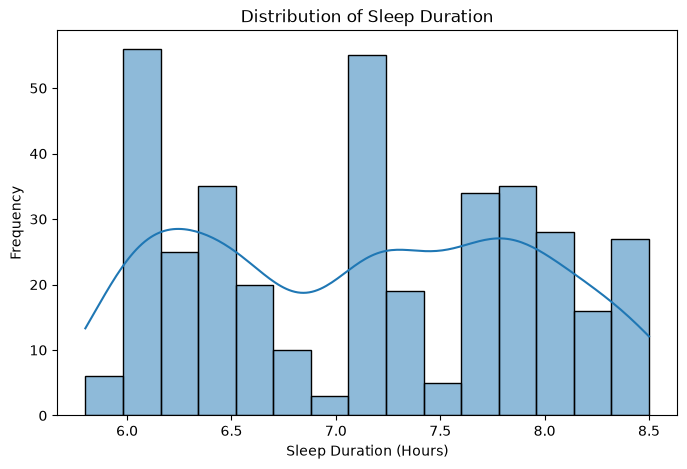

In [13]:
# sleep duration distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df,x="Sleep Duration",bins=15,kde=True)
plt.title("Distribution of Sleep Duration")
plt.xlabel("Sleep Duration (Hours)")
plt.ylabel("Frequency")
plt.show()

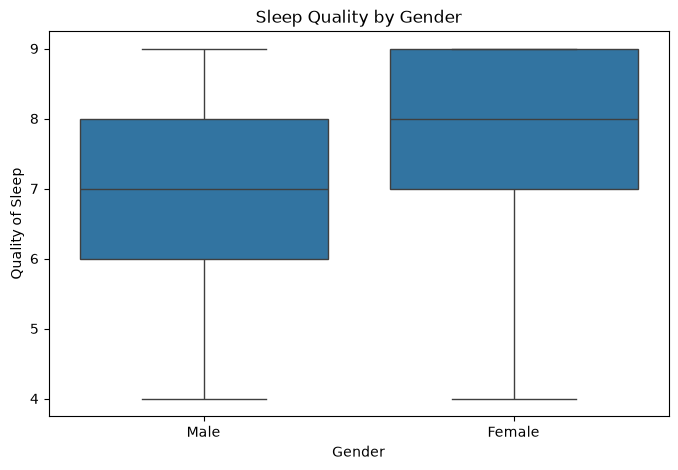

In [14]:
# sleep quality by gender

plt.figure(figsize=(8, 5))
sns.boxplot( data=df,x="Gender",y="Quality of Sleep")
plt.title("Sleep Quality by Gender")
plt.show()

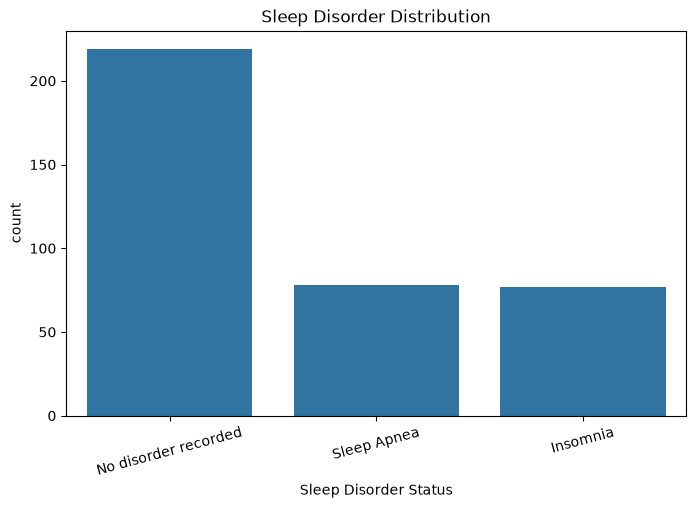

In [15]:
# sleep disorders

plt.figure(figsize=(8, 5))

sns.countplot(data=df,x="Sleep Disorder Status")
plt.title("Sleep Disorder Distribution")
plt.xticks(rotation=15)
plt.show()

<Axes: >

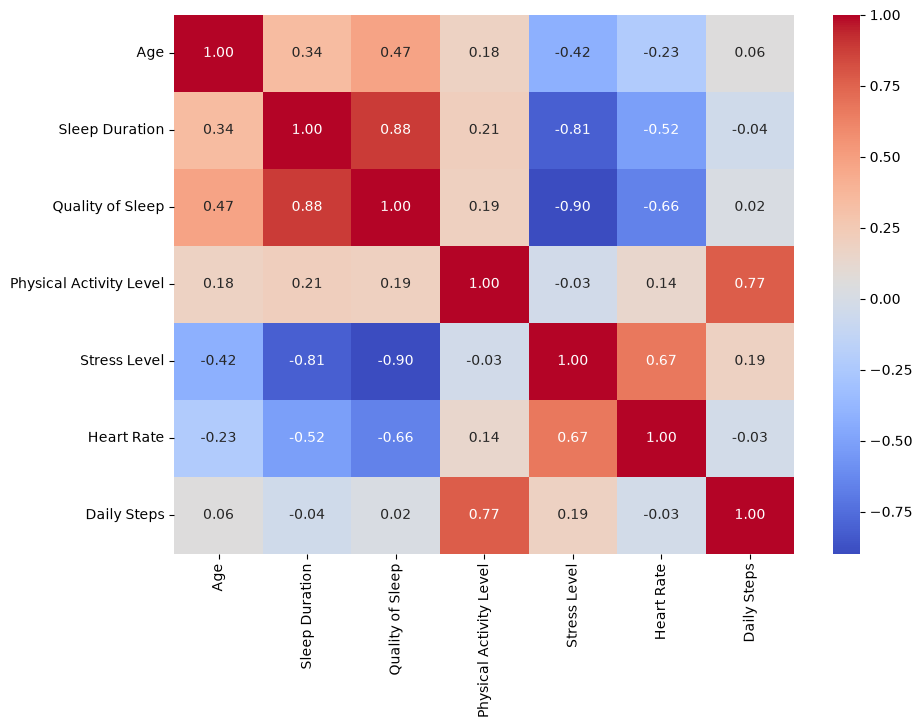

In [16]:
# correlation heatmap

numeric_cols = ["Age","Sleep Duration","Quality of Sleep","Physical Activity Level","Stress Level","Heart Rate","Daily Steps"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")


In [22]:
# Sleep quality by occupation

occupation_sleep = (df.groupby("Occupation")["Quality of Sleep"].mean().sort_values(ascending=False))
print(occupation_sleep)

Occupation
Engineer                8.412698
Lawyer                  7.893617
Accountant              7.891892
Nurse                   7.369863
Manager                 7.000000
Teacher                 6.975000
Doctor                  6.647887
Software Engineer       6.500000
Salesperson             6.000000
Scientist               5.000000
Sales Representative    4.000000
Name: Quality of Sleep, dtype: float64
